# Predicting Flight Cancellations with PySpark

**Revised version of a group project** for the Big Data course of the Master's in Data Analytics and Decision Support Systems (ISCAC – Coimbra Business School).

The goal is to predict, using only information known **before departure**, whether a US domestic flight will be cancelled.
The data covers 2017 and 2018 (≈12.9 million flights), and only ≈1.5% of flights are cancelled.

That imbalance is the central issue of this notebook. In the original submission, four models reached 98.5% accuracy,
which is exactly the share of flights that were **not** cancelled: the models predicted "not cancelled" for every flight.
This version shows why that happened and fixes it:

1. Leakage control – only features available before departure are used (the original included `DIVERTED`, which is only known after the flight).
2. Time-based validation – train on 2017, test on 2018.
3. Class weights to counter the imbalance.
4. Metrics that measure the minority class: precision, recall and F1 for cancellations, PR-AUC, and recall in the top 5% riskiest flights.
5. A decision threshold chosen on validation data instead of the default 0.5.

## 1. Setup

In [ ]:
import os, sys, glob

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    import importlib.util, subprocess
    if importlib.util.find_spec("pyspark") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

# Folder with the yearly CSV files from Kaggle (2017.csv and 2018.csv). See data/README.md.
DATA_DIR = os.environ.get(
    "FLIGHTS_DATA_DIR",
    "/content/drive/MyDrive/flights-data" if IN_COLAB else "../data",
)
YEARS = [2017, 2018]
TRAIN_YEAR, TEST_YEAR = 2017, 2018
SEED = 42
# Share of 2017 used for training. Lower it (e.g. 0.3) if the free Colab runtime is too slow.
TRAIN_FRACTION = float(os.environ.get("TRAIN_FRACTION", 0.3))
FIG_DIR, RESULTS_DIR = "../figures", "../results"
if IN_COLAB:
    FIG_DIR, RESULTS_DIR = f"{DATA_DIR}/figures", f"{DATA_DIR}/results"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.functions import vector_to_array

spark = (
    SparkSession.builder.appName("flight-cancellations")
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "8g"))
    .config("spark.sql.shuffle.partitions", "64")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})

## 2. Data

Source: *Airline Delay and Cancellation Data, 2009–2018* (Kaggle), compiled from the US Bureau of Transportation Statistics.
Every column is read as text and only the needed columns are cast, which avoids a second pass over 1.6 GB for schema inference.

In [ ]:
paths = [f"{DATA_DIR}/{y}.csv" for y in YEARS]
missing = [p for p in paths if not os.path.exists(p)]
assert not missing, f"Missing files: {missing}. See data/README.md."

raw = spark.read.csv(paths, header=True, inferSchema=False)
print(f"{raw.count():,} rows, {len(raw.columns)} columns")

12,888,067 rows, 28 columns


In [ ]:
LABEL = "CANCELLED"

def hhmm_to_hour(col):
    # 'CRS_DEP_TIME' is stored as hhmm (e.g. 1435); 2400 means midnight.
    return (F.floor(F.col(col).cast("double") / 100) % 24).cast("int")

df = (
    raw.withColumn("date", F.to_date("FL_DATE"))
    .select(
        F.year("date").alias("YEAR"),
        F.month("date").alias("MONTH"),
        F.dayofmonth("date").alias("DAY_OF_MONTH"),
        F.dayofweek("date").alias("DAY_OF_WEEK"),
        "date",
        "OP_CARRIER", "ORIGIN", "DEST",
        hhmm_to_hour("CRS_DEP_TIME").alias("DEP_HOUR"),
        hhmm_to_hour("CRS_ARR_TIME").alias("ARR_HOUR"),
        F.col("CRS_ELAPSED_TIME").cast("double").alias("CRS_ELAPSED_TIME"),
        F.col("DISTANCE").cast("double").alias("DISTANCE"),
        F.col("CANCELLED").cast("double").cast("int").alias(LABEL),
        "CANCELLATION_CODE",
    )
)

# Scheduled congestion: how many departures the origin airport has planned that day and in that hour.
# This comes from the schedule itself, so it is known in advance.
df = (
    df.join(df.groupBy("ORIGIN", "date").agg(F.count("*").alias("ORIGIN_DAY_FLIGHTS")), ["ORIGIN", "date"])
      .join(df.groupBy("ORIGIN", "date", "DEP_HOUR").agg(F.count("*").alias("ORIGIN_HOUR_FLIGHTS")),
            ["ORIGIN", "date", "DEP_HOUR"])
)

before = df.count()
df = df.dropna(subset=["YEAR", "DEP_HOUR", "ARR_HOUR", "DISTANCE", LABEL])
df = df.fillna({"CRS_ELAPSED_TIME": 0.0})
df = df.cache()
print(f"Dropped {before - df.count():,} rows with missing key fields")

Dropped 0 rows with missing key fields


## 3. Exploratory analysis

In [ ]:
overview = (
    df.groupBy("YEAR")
      .agg(F.count("*").alias("flights"), F.sum(LABEL).alias("cancelled"))
      .withColumn("cancel_rate_%", F.round(100 * F.col("cancelled") / F.col("flights"), 2))
      .orderBy("YEAR").toPandas()
)
overview

,YEAR,flights,cancelled,cancel_rate_%
0,2017,5674621,82693,1.46
1,2018,7213446,116584,1.62


Cancellation codes in the source data: **A** carrier, **B** weather, **C** National Air System (NAS, traffic control and airport operations), **D** security.
The code is only known after the flight is cancelled, so it is used here for description and never as a feature.

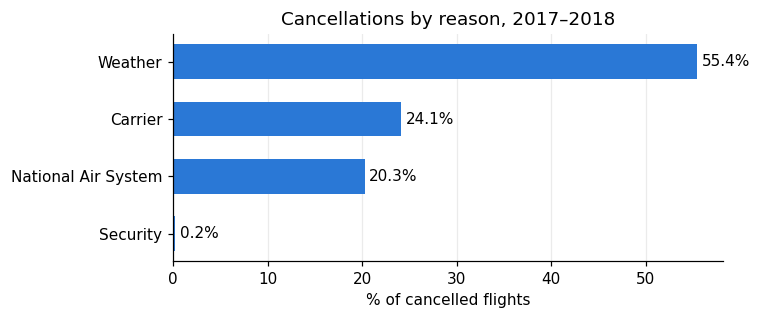

In [ ]:
reason_names = {"A": "Carrier", "B": "Weather", "C": "National Air System", "D": "Security"}
reasons = (
    df.filter(F.col(LABEL) == 1).groupBy("CANCELLATION_CODE").count().toPandas()
      .assign(reason=lambda d: d["CANCELLATION_CODE"].map(reason_names).fillna("Unknown"))
      .assign(share=lambda d: 100 * d["count"] / d["count"].sum())
      .sort_values("share")
)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(reasons["reason"], reasons["share"], color=BLUE, height=0.6)
for y, v in enumerate(reasons["share"]):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center")
ax.set_xlabel("% of cancelled flights")
ax.set_title("Cancellations by reason, 2017–2018")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/cancellation_reasons.png", bbox_inches="tight"); plt.show()

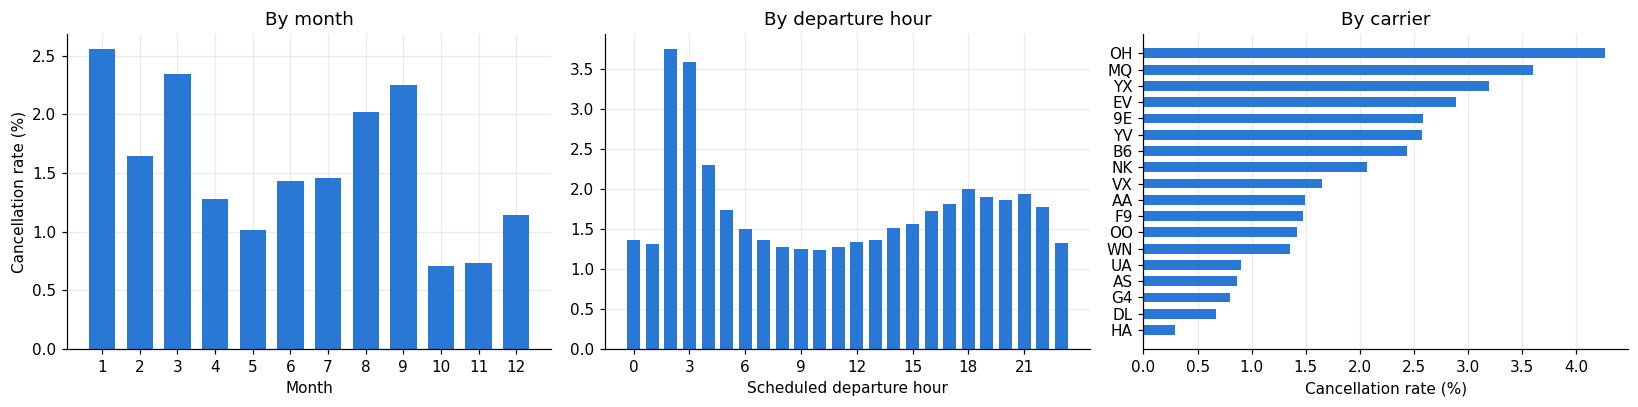

In [ ]:
def rate_by(col):
    return (df.groupBy(col).agg((100 * F.avg(LABEL)).alias("rate"), F.count("*").alias("flights"))
              .orderBy(col).toPandas())

by_month, by_hour = rate_by("MONTH"), rate_by("DEP_HOUR")
by_carrier = rate_by("OP_CARRIER").sort_values("rate")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(by_month["MONTH"], by_month["rate"], color=BLUE, width=0.7)
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel("Month")
axes[1].bar(by_hour["DEP_HOUR"], by_hour["rate"], color=BLUE, width=0.7)
axes[1].set_xticks(range(0, 24, 3)); axes[1].set_xlabel("Scheduled departure hour")
axes[2].barh(by_carrier["OP_CARRIER"], by_carrier["rate"], color=BLUE, height=0.6)
axes[2].set_xlabel("Cancellation rate (%)"); axes[2].grid(axis="y", visible=False)
axes[0].set_ylabel("Cancellation rate (%)")
for ax, t in zip(axes, ["By month", "By departure hour", "By carrier"]):
    ax.set_title(t)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/cancellation_rates.png", bbox_inches="tight"); plt.show()

## 4. Features and split

Only information available when the flight is scheduled is used. Excluded on purpose: actual times, delays, taxi times,
`DIVERTED` and `CANCELLATION_CODE`, which are all recorded after the flight.

Validation is time-based: models are trained on 2017 and tested on 2018, which is closer to how a model would be used in practice.
10% of 2017 is held out to choose the decision threshold, so the 2018 test set is never used for any choice.

In [ ]:
CAT_COLS = ["OP_CARRIER", "ORIGIN", "DEST"]
NUM_COLS = ["MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK", "DEP_HOUR", "ARR_HOUR",
            "CRS_ELAPSED_TIME", "DISTANCE", "ORIGIN_DAY_FLIGHTS", "ORIGIN_HOUR_FLIGHTS"]

model_df = df.select(*CAT_COLS, *NUM_COLS, "YEAR", LABEL)
train_full = model_df.filter(F.col("YEAR") == TRAIN_YEAR)
if TRAIN_FRACTION < 1:
    train_full = train_full.sample(fraction=TRAIN_FRACTION, seed=SEED)
test = model_df.filter(F.col("YEAR") == TEST_YEAR).cache()
train, val = train_full.randomSplit([0.9, 0.1], seed=SEED)

# Class weights: each class contributes the same total weight to the loss.
n_pos, n_tot = train.agg(F.sum(LABEL), F.count("*")).first()
w_pos, w_neg = n_tot / (2 * n_pos), n_tot / (2 * (n_tot - n_pos))
train = train.withColumn("weight", F.when(F.col(LABEL) == 1, w_pos).otherwise(w_neg)).cache()
val = val.cache()

print(f"train {train.count():,} | validation {val.count():,} | test {test.count():,}")
print(f"positive rate in train: {n_pos / n_tot:.2%}  ->  weights: cancelled {w_pos:.1f}, not cancelled {w_neg:.3f}")

train 1,531,825 | validation 171,148 | test 7,213,446
positive rate in train: 1.44%  ->  weights: cancelled 34.6, not cancelled 0.507


## 5. The accuracy trap

Before training anything: a "model" that always predicts *not cancelled*. Its weighted precision, recall and F1
match the values reported for the four models in the original report (≈0.969 / 0.985 / 0.977).
Weighted metrics are averaged by class size, so with 98.5% of flights in one class they mostly describe that class.

In [ ]:
baseline = test.withColumn("prediction", F.lit(0.0)).withColumn(LABEL, F.col(LABEL).cast("double"))
mc = MulticlassClassificationEvaluator(labelCol=LABEL, predictionCol="prediction")
for m in ["accuracy", "weightedPrecision", "weightedRecall", "f1"]:
    print(f"{m:>18}: {mc.evaluate(baseline, {mc.metricName: m}):.3f}")
print(f"{'recall (cancelled)':>18}: 0.000  <- not one cancellation detected")

          accuracy: 0.984
 weightedPrecision: 0.968
    weightedRecall: 0.984
                f1: 0.976
recall (cancelled): 0.000  <- not one cancellation detected


## 6. Models

Three Spark MLlib models, all trained with the class weights:

- **Logistic regression** – linear baseline, with one-hot encoded categories and scaled features.
- **Random forest**
- **Gradient-boosted trees (GBT)**

For the tree models, carrier and airports are passed as indexed categorical features, so `maxBins` must be at least the number of airports.

In [ ]:
indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in CAT_COLS]
max_cats = max(train.select(c).distinct().count() for c in CAT_COLS) + 2

tree_features = NUM_COLS + [f"{c}_idx" for c in CAT_COLS]
tree_assembler = VectorAssembler(inputCols=tree_features, outputCol="features")

lr_pipeline = Pipeline(stages=indexers + [
    OneHotEncoder(inputCols=[f"{c}_idx" for c in CAT_COLS], outputCols=[f"{c}_ohe" for c in CAT_COLS], handleInvalid="keep"),
    VectorAssembler(inputCols=NUM_COLS + [f"{c}_ohe" for c in CAT_COLS], outputCol="raw_features"),
    StandardScaler(inputCol="raw_features", outputCol="features", withMean=False),
    LogisticRegression(labelCol=LABEL, weightCol="weight", maxIter=50, regParam=0.001),
])
rf_pipeline = Pipeline(stages=indexers + [tree_assembler, RandomForestClassifier(
    labelCol=LABEL, weightCol="weight", numTrees=60, maxDepth=12, maxBins=max_cats,
    subsamplingRate=0.7, featureSubsetStrategy="sqrt", seed=SEED)])
gbt_pipeline = Pipeline(stages=indexers + [tree_assembler, GBTClassifier(
    labelCol=LABEL, weightCol="weight", maxIter=60, maxDepth=6, maxBins=max_cats, stepSize=0.1, seed=SEED)])

pipelines = {"Logistic regression": lr_pipeline, "Random forest": rf_pipeline, "Gradient-boosted trees": gbt_pipeline}

In [ ]:
import time

fitted = {}
for name, pipe in pipelines.items():
    t0 = time.perf_counter()
    fitted[name] = pipe.fit(train)
    print(f"{name}: trained in {(time.perf_counter() - t0) / 60:.1f} min")

Logistic regression: trained in 2.3 min
Random forest: trained in 23.0 min
Gradient-boosted trees: trained in 35.3 min


## 7. Evaluation

For each model:

- **ROC-AUC** and **PR-AUC** (area under the precision–recall curve). For PR-AUC a random model scores the positive rate (≈0.015), so that is the reference.
- A **decision threshold** chosen on the 2017 validation set to maximise F1 for the cancelled class.
- **Precision, recall and F1 for cancellations** on 2018 at that threshold, plus accuracy for comparison.
- **Recall in the top 5%**: if an operations team reviewed the 5% of flights with the highest predicted risk, what share of all cancellations would they see?

In [ ]:
def scores(model, data):
    # Keep only label and probability of 'cancelled'
    return (model.transform(data)
                 .select(F.col(LABEL).cast("double").alias(LABEL), vector_to_array("probability")[1].alias("p1")))

def best_f1_threshold(scored):
    pdf = scored.toPandas()
    prec, rec, thr = precision_recall_curve(pdf[LABEL], pdf["p1"])
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.argmax(f1[:-1])])

def evaluate(scored, threshold):
    pred = scored.withColumn("yhat", (F.col("p1") >= threshold).cast("double"))
    r = pred.agg(
        F.sum(((F.col("yhat") == 1) & (F.col(LABEL) == 1)).cast("int")).alias("tp"),
        F.sum(((F.col("yhat") == 1) & (F.col(LABEL) == 0)).cast("int")).alias("fp"),
        F.sum(((F.col("yhat") == 0) & (F.col(LABEL) == 1)).cast("int")).alias("fn"),
        F.sum(((F.col("yhat") == 0) & (F.col(LABEL) == 0)).cast("int")).alias("tn"),
    ).first()
    tp, fp, fn, tn = r["tp"], r["fp"], r["fn"], r["tn"]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    q95 = scored.approxQuantile("p1", [0.95], 0.001)[0]
    top = scored.filter(F.col("p1") >= q95).agg(F.sum(LABEL)).first()[0] or 0
    bce = BinaryClassificationEvaluator(labelCol=LABEL, rawPredictionCol="p1")
    return {
        "threshold": threshold,
        "roc_auc": bce.evaluate(scored, {bce.metricName: "areaUnderROC"}),
        "pr_auc": bce.evaluate(scored, {bce.metricName: "areaUnderPR"}),
        "precision": precision, "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "accuracy": (tp + tn) / (tp + fp + fn + tn),
        "recall_top5%": top / (tp + fn),
        "confusion": [[tn, fp], [fn, tp]],
    }

In [ ]:
pos_rate = test.agg(F.avg(LABEL)).first()[0]
results = {"Always 'not cancelled'": {
    "threshold": np.nan, "roc_auc": 0.5, "pr_auc": pos_rate, "precision": 0.0, "recall": 0.0, "f1": 0.0,
    "accuracy": 1 - pos_rate, "recall_top5%": 0.05, "confusion": None}}
test_scores = {}

for name, model in fitted.items():
    t = best_f1_threshold(scores(model, val))
    test_scores[name] = scores(model, test).cache()
    results[name] = evaluate(test_scores[name], t)

summary = pd.DataFrame(results).T.drop(columns="confusion")
summary.to_csv(f"{RESULTS_DIR}/test_metrics_2018.csv")
summary.astype(float).round(3)

,threshold,roc_auc,pr_auc,precision,recall,f1,accuracy,recall_top5%
Always 'not cancelled',NaN,0.500,0.016,0.000,0.000,0.000,0.984,0.050
Logistic regression,0.712,0.634,0.026,0.032,0.140,0.052,0.918,0.100
Random forest,0.735,0.662,0.029,0.042,0.013,0.019,0.979,0.129
Gradient-boosted trees,0.867,0.669,0.030,0.039,0.076,0.051,0.954,0.126


In [ ]:
for name, r in results.items():
    if r["confusion"] is None:
        continue
    (tn, fp), (fn, tp) = r["confusion"]
    print(f"{name}  (threshold {r['threshold']:.3f})")
    print(f"                    predicted no   predicted yes")
    print(f"  not cancelled   {tn:>14,} {fp:>15,}")
    print(f"  cancelled       {fn:>14,} {tp:>15,}\n")

Logistic regression  (threshold 0.712)
                    predicted no   predicted yes
  not cancelled        6,602,711         494,151
  cancelled              100,320          16,264

Random forest  (threshold 0.735)
                    predicted no   predicted yes
  not cancelled        7,062,928          33,934
  cancelled              115,113           1,471

Gradient-boosted trees  (threshold 0.867)
                    predicted no   predicted yes
  not cancelled        6,874,409         222,453
  cancelled              107,668           8,916



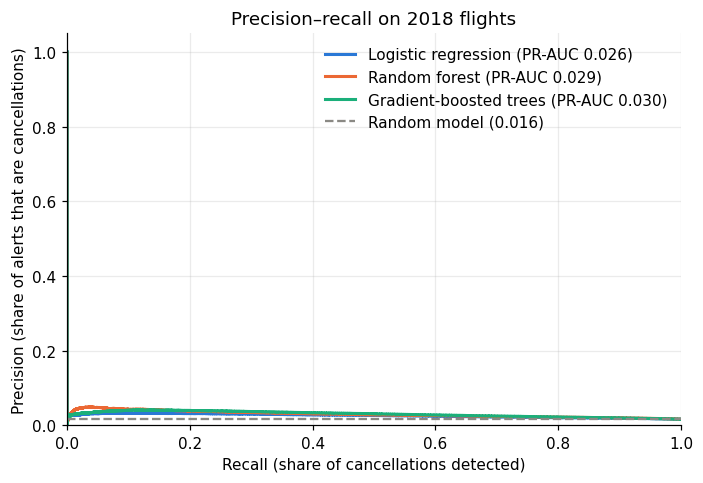

In [ ]:
sample = {name: s.sample(fraction=min(1.0, 1_000_000 / test.count()), seed=SEED).toPandas()
          for name, s in test_scores.items()}

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for (name, pdf), color in zip(sample.items(), [BLUE, ORANGE, AQUA]):
    prec, rec, _ = precision_recall_curve(pdf[LABEL], pdf["p1"])
    ax.plot(rec, prec, color=color, lw=2, label=f"{name} (PR-AUC {results[name]['pr_auc']:.3f})")
ax.axhline(pos_rate, color=GREY, lw=1.5, ls="--", label=f"Random model ({pos_rate:.3f})")
ax.set_xlabel("Recall (share of cancellations detected)")
ax.set_ylabel("Precision (share of alerts that are cancellations)")
ax.set_title("Precision–recall on 2018 flights")
ax.set_xlim(0, 1); ax.set_ylim(0, None); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/precision_recall.png", bbox_inches="tight"); plt.show()

## 8. What drives the predictions

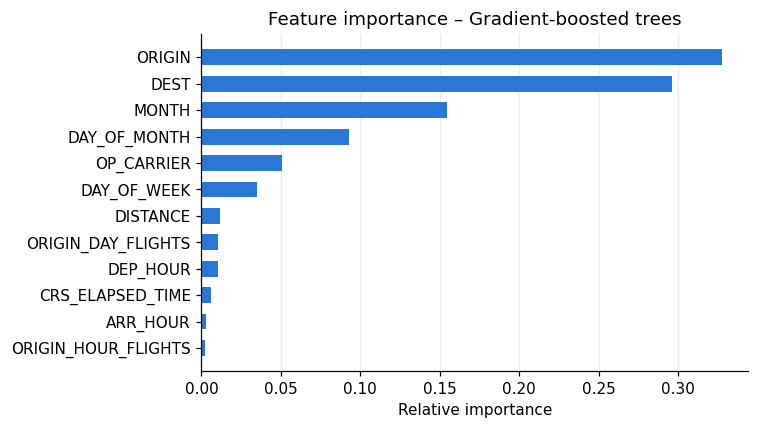

In [ ]:
best_tree = max(["Random forest", "Gradient-boosted trees"], key=lambda n: results[n]["pr_auc"])
importances = (pd.Series(fitted[best_tree].stages[-1].featureImportances.toArray(),
                         index=[f.replace("_idx", "") for f in tree_features])
                 .sort_values())

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importances.index, importances.values, color=BLUE, height=0.6)
ax.set_xlabel("Relative importance"); ax.set_title(f"Feature importance – {best_tree}")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/feature_importance.png", bbox_inches="tight"); plt.show()

## 9. Conclusions

Run with `TRAIN_FRACTION = 0.3` (1.53 million training flights from 2017); tested on all 7.2 million flights of 2018, of which 1.62% were cancelled.

**The accuracy trap is confirmed.** Predicting "not cancelled" for every flight gives 98.4% accuracy and weighted precision, recall and F1 of 0.968, 0.984 and 0.976, practically the same values the original report presented as good results, while detecting no cancellations at all.

**With honest metrics, schedule data has only a modest signal.** The best models reach a PR-AUC of 0.030 (gradient-boosted trees) and 0.029 (random forest), about twice the 0.016 of a random model, and a ROC-AUC of 0.63 to 0.67.
Ranking flights by predicted risk is where the models are most useful: the 5% riskiest flights contain 12.6% to 12.9% of all cancellations, about 2.5 times what a random selection would catch.
As a yes/no alarm they are weak: at the threshold chosen on 2017 data, logistic regression detects 14% of cancellations, but only about 3 in every 100 alerts are real cancellations.

**What drives the predictions.** Origin and destination airports, month and day of the month carry most of the importance, with carrier and day of the week behind.
The weight of month and day of the month suggests the models partly learn which specific periods of 2017 were bad, and these do not repeat in 2018. This also explains why the thresholds chosen on 2017 transfer poorly: the random forest, for example, detects only 1.3% of cancellations at its threshold.

**Limitations.** Weather causes 55% of cancellations, and the data has no weather information. Cancellations also cluster on specific days (storms, system outages) that a flight-level model without that context cannot anticipate.

**Next steps.** Add weather forecasts per airport and day, use historical cancellation rates per route computed only from past data, and evaluate month by month to check how stable the model is across the year.


In [ ]:
spark.stop()